# Multihop-easy few-shot lens benchmark — GPT-2 XL

**Question.** GPT-2 XL is a base model: given a zero-shot multihop-easy prompt such as *"The food obtained from the striped flying insect that lives in a hive is"*, it usually continues with a description instead of the answer. With three solved demonstrations in front of the same question ([`lens-eval-multihop-easy-fewshot`](../../../data/evaluations/lens-eval-multihop-easy-fewshot.json)), does the model answer, and does the fitted Jacobian lens read the unspoken intermediate (*bee*) at the final prompt token better than the logit lens?

**Answer.** Demonstrations make GPT-2 XL answer: generated accuracy rises from 17.0% (34/200) zero-shot to 44.5% (89/200) few-shot, mostly in geography (41% → 97%) and word forms (29% → 54%); opposites stay near zero because the model answers with the intermediate itself. The intermediate also becomes more readable at the final token for both lenses, but the **J-lens does not beat the logit lens** here: inner-layer equal-family pass@10 is 56.7% for the J-lens and 62.7% for the logit lens few-shot (zero-shot: 34.9% vs 47.5%), and the logit lens is ahead in every split (dev, test, generated correct). Shifted controls stay at 1–2%, but in-context demo answers reach 41–46%, and in the layer profile the target rises before the intermediate, so the readout does not show a bridge that precedes the answer.

This is the multihop-easy part of [the latent-bridge v2 / Anthropic benchmark](../latent_bridge_v2/latent_bridge_v2_lens_benchmark.ipynb) with the same model, lens, encoding, strict scoring, generation and grouped aggregation, run on the few-shot dataset. The zero-shot dataset goes through the same pass as the reference, so both columns of every table come from one run.

## Method

* **Data.** Both datasets have the same 200 prompts (100 base items × 2 phrasings, 5 families) with identical names, intermediates, targets, `group_id` and dev/test splits; the few-shot `prompt` is three `"{prompt} {target}."` demonstration lines followed by the zero-shot question. The builder guarantees that no demonstration contains the item's intermediate or target as a whole word. Details: [data/evaluations/README.md](../../../data/evaluations/README.md#lens-eval-multihop-easy-fewshot), [builder](../../model_agnostic/multihop_easy/multihop_easy_fewshot_build.ipynb).
* **Readout.** Final prompt token (the token before the answer), every block output; inner layers exclude the shared final block. Strict whole-token ranks: the best exact decoded spelling with case and leading-space variants, no prefix fallback, ties by token ID, pre-softcap lexical scores.
* **Words.** `intermediate` is the annotated bridge; `control` is the evaluator's shifted-item bridge (not family matched); `target` is the answer. For the few-shot prompts we add `demo target`: the three demonstration answers, which *are* in the context, so they measure in-context copying of a recent answer rather than latent reasoning. Demo targets are scored in the same batched pass, as a separate pseudo-dataset over the same prompts.
* **Model answers.** One greedy continuation (`MAX_NEW_TOKENS`) per prompt, scored by `jlens.generated_answers.score_answer` on its first completed phrase, with one leading article removed (`STRIP_ARTICLES`). The `generated correct` split keeps the prompts the model answers correctly *in that dataset*.
* **Aggregation.** As in the reference notebook: word hits are averaged within a prompt, phrasings within `base_id`, base items within a family, then families equally (**equal-family macro**). Unsupported words keep null hits and are excluded with their counts shown. pass@k means the best rank over the scope's layers is ≤ k. No uncertainty intervals and no dev-set tuning.
* **Compute.** One shared model pass per right-padded, length-sorted batch for both lenses; generations are left-padded batches. Ranks and continuations are cached in `runs/` keyed by a manifest of inputs, implementation files and notebook code.

In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

REPO = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "batched_evaluation.py").is_file()), None,
)
if REPO is None:
    raise RuntimeError("Open this notebook from a repository checkout; run uv sync --extra dev first.")
sys.path.insert(0, str(REPO))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Markdown, display
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer

import jlens
from jlens.batched_evaluation import evaluate_paired_batched
from jlens.evaluation import identity_lens, load_eval
from jlens.generated_answers import generate_answers_batched, score_generations
from jlens.strict_scoring import DecodedSpellings, ExplicitPromptModel

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## Configuration

The same GPT-2 XL lens and settings as the reference benchmark. `RUN_MODE = "smoke"` runs the pipeline offline on a random tiny Llama with identity Jacobians (one base item per family), without downloading weights.

In [3]:
RUN_MODE = "pretrained"  # "smoke" runs the offline pipeline check
MODEL_ID = "openai-community/gpt2-xl"
MODEL_REVISION = "main"  # Pin a Hub commit for a reproducible trained run.
LENS_PATH = Path(os.environ.get(
    "JLENS_LENS_PATH", REPO / "runs/gpt2-xl-convergence/snapshot_lens_134.pt",
)).expanduser()
FIT_PROVENANCE = {  # snapshot_lens_134.pt: notebooks/gpt2-xl/jacobian_lens/jacobian_logit_lens_dataset.ipynb
    "model_id": MODEL_ID,
    "model_revision": None,  # not recorded at fit time
    "dtype": "float32",
    "corpus_mix": "jlens.evaluation.FIT_MIX x 0.25 = 134 prompts",
    "sequence_length": 128,
    "dimension_batch_size": None,  # selected automatically at fit time, not recorded
}
ZERO_SHOT, FEW_SHOT = "multihop-easy", "multihop-easy-fewshot"
DEMO_TARGETS = f"{FEW_SHOT}/demo-targets"  # pseudo-dataset: same prompts, demo answers as words
BOS_POLICY = "prepend"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32
BATCH_SIZE = 32
MAX_BATCH_TOKENS = 4096
MAX_SEQ_LEN = 512
POSITION_CHUNK_SIZE = 8
RANK_CHUNK_SIZE = 8
MAX_NEW_TOKENS = 24  # greedy continuation per prompt, scored as a completed answer
STRIP_ARTICLES = True  # base models continue "... is" with "the"/"a" before the answer
K_VALUES = [1, 2, 5, 10, 20, 50, 100]
K = 10
CACHE_ROOT = REPO / "runs/multihop-easy-fewshot-benchmark"
FORCE_RECOMPUTE = False
COLORS = {"logit lens": "#eb6834", "J-lens": "#2a78d6"}
STYLES = {"intermediate": "-", "control": "--", "demo target": ":", "target": "-."}

if RUN_MODE not in {"smoke", "pretrained"}:
    raise ValueError("RUN_MODE must be smoke or pretrained")

## Data

The few-shot items must match the zero-shot items one to one in everything except the prompt. Demo targets are taken from the named demonstration items; a demo target equal to the item's own intermediate or target (case-insensitive) would be dropped, though the builder already excludes this.

In [4]:
easy_evals = {name: load_eval(str(REPO), name) for name in [ZERO_SHOT, FEW_SHOT]}
zero_by_name = {item["name"]: item for item in easy_evals[ZERO_SHOT]}
assert [item["name"] for item in easy_evals[FEW_SHOT]] == list(zero_by_name)
for item in easy_evals[FEW_SHOT]:
    source = zero_by_name[item["name"]]
    for field in ["target", "intermediates", "base_id", "family", "group_id", "split", "relation"]:
        assert item[field] == source[field], (item["name"], field)
    assert item["prompt"].endswith(source["prompt"]) and item["question"] == source["prompt"]
if RUN_MODE == "smoke":
    smoke_bases = set(pd.DataFrame(easy_evals[ZERO_SHOT]).drop_duplicates("family").base_id)
    easy_evals = {name: [item for item in items if item["base_id"] in smoke_bases]
                  for name, items in easy_evals.items()}

demo_items = []
for item in easy_evals[FEW_SHOT]:
    own = {word.casefold() for word in [*item["intermediates"], item["target"]]}
    targets = [zero_by_name[demo]["target"] for demo in item["demos"]]
    demo_items.append({"name": item["name"], "prompt": item["prompt"],
                       "intermediates": [t for t in targets if t.casefold() not in own]})
assert all(len(item["intermediates"]) == 3 for item in demo_items)
selected_evals = {**easy_evals, DEMO_TARGETS: demo_items}

easy_metadata = pd.DataFrame(easy_evals[ZERO_SHOT])[
    ["name", "base_id", "family", "relation", "group_id", "split", "template_id"]
].rename(columns={"name": "item"})
assert easy_metadata.groupby("base_id").size().eq(2).all()
fewshot_frame = pd.DataFrame(easy_evals[FEW_SHOT])
display(pd.DataFrame([
    {"dataset": name, "prompts": len(items), "base items": len({i["base_id"] for i in items}),
     "median prompt chars": int(np.median([len(i["prompt"]) for i in items]))}
    for name, items in easy_evals.items()
]).set_index("dataset"))
display(fewshot_frame.groupby("family").agg(
    prompts=("name", "size"), demo_relation_match=("demo_relation_match", "sum"),
))
print(fewshot_frame.prompt.iloc[0])

,prompts,base items,median prompt chars
dataset,,,
multihop-easy,200,100,66
multihop-easy-fewshot,200,100,289


,prompts,demo_relation_match
family,,
animals,40,30
arithmetic,32,30
geography,64,32
opposites,40,40
word_forms,24,24


The food obtained from the female farm bird that clucks is eggs.
The textile fiber obtained from the farm animal that says baa is wool.
The name for a baby of the farm animal that says baa is lamb.
The food obtained from the striped flying insect that lives in a hive is


## Model identity and cache provenance

As in the reference notebook, the cache key covers the selected prompts, model/config revision, full tokenizer serialization, BOS/dtype/device, lens SHA-256, fit metadata, chunk settings, implementation files, package versions and notebook code. A cache hit skips weight loading and all forwards.

In [5]:
def digest_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()


if RUN_MODE == "smoke":
    from tokenizers import Regex, Tokenizer, models, pre_tokenizers
    from transformers import LlamaConfig, PreTrainedTokenizerFast

    splitter = pre_tokenizers.Sequence([
        pre_tokenizers.Split(Regex(r"\n"), behavior="isolated"),
        pre_tokenizers.Split(Regex(r"[^\S\n]+"), behavior="removed"),
    ])
    texts = [item["prompt"] for items in selected_evals.values() for item in items]
    labels = [word for items in easy_evals.values() for item in items
              for word in [*item["intermediates"], item["target"]]]
    labels += [word for item in demo_items for word in item["intermediates"]]
    pieces = {piece for text in texts + labels for piece, _ in splitter.pre_tokenize_str(text)}
    vocab = {token: i for i, token in enumerate(["[UNK]", "[BOS]", "[PAD]", *sorted(pieces)])}
    backend = Tokenizer(models.WordLevel(vocab, unk_token="[UNK]"))
    backend.pre_tokenizer = splitter
    tokenizer = PreTrainedTokenizerFast(
        tokenizer_object=backend, unk_token="[UNK]", bos_token="[BOS]", pad_token="[PAD]",
    )
    config = LlamaConfig(
        vocab_size=len(tokenizer), hidden_size=16, intermediate_size=32,
        num_hidden_layers=3, num_attention_heads=2, num_key_value_heads=1,
        max_position_embeddings=MAX_SEQ_LEN, bos_token_id=tokenizer.bos_token_id,
        pad_token_id=tokenizer.pad_token_id, eos_token_id=None,
    )
    run_model_id, resolved_revision = "offline/random-tiny-llama", "seed-0"
    lens_identity = "identity-matrices-v1"
    fit_metadata = {"method": "identity; no fitting", "corpus_mix": None,
                    "sequence_length": None, "dimension_batch_size": None}
    run_device, run_dtype = "cpu", torch.float32
else:
    if not LENS_PATH.is_file():
        raise FileNotFoundError(f"Set LENS_PATH to a fitted lens for {MODEL_ID}: {LENS_PATH}")
    if FIT_PROVENANCE["model_id"] != MODEL_ID:
        raise ValueError("Lens provenance model_id differs from MODEL_ID")
    config = AutoConfig.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
    resolved_revision = getattr(config, "_commit_hash", None)
    if resolved_revision is None:
        # Newer transformers no longer record the commit on the config; the snapshot directory is named by it.
        from huggingface_hub import snapshot_download
        resolved_revision = Path(snapshot_download(
            MODEL_ID, revision=MODEL_REVISION, allow_patterns=["config.json"],
        )).name
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=resolved_revision, use_fast=True)
    if FIT_PROVENANCE["model_revision"] not in {None, resolved_revision}:
        raise ValueError("Lens provenance revision differs from the selected model")
    run_model_id, lens_identity = MODEL_ID, digest_file(LENS_PATH)
    fit_metadata = FIT_PROVENANCE.copy()
    run_device, run_dtype = DEVICE, DTYPE

implementation = [
    "jlens/batched_evaluation.py", "jlens/evaluation.py", "jlens/hf.py", "jlens/readout.py",
    "jlens/strict_scoring.py", "jlens/lens.py", "jlens/hooks.py", "jlens/generated_answers.py",
]
notebook_path = REPO / "notebooks/gpt2-xl/multihop_easy/multihop_easy_fewshot_lens_benchmark.ipynb"
notebook_code = ["".join(cell["source"]) for cell in json.loads(notebook_path.read_text())["cells"]
                 if cell["cell_type"] == "code"]
manifest = {
    "schema": 1, "mode": RUN_MODE, "model": run_model_id, "revision": resolved_revision,
    "config": config.to_dict(), "tokenizer": tokenizer.backend_tokenizer.to_str(),
    "special_tokens": tokenizer.special_tokens_map, "bos_policy": BOS_POLICY,
    "dtype": str(run_dtype), "device": run_device, "lens_sha256_or_identity": lens_identity,
    "fit": fit_metadata, "evals_sha256": digest_json(selected_evals),
    "implementation": {name: digest_file(REPO / name) for name in implementation},
    "notebook_code_sha256": digest_json(notebook_code),
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
    "matmul_precision": torch.get_float32_matmul_precision(),
    "batch_size": BATCH_SIZE, "max_batch_tokens": MAX_BATCH_TOKENS,
    "max_seq_len": MAX_SEQ_LEN, "position_chunk_size": POSITION_CHUNK_SIZE,
    "rank_chunk_size": RANK_CHUNK_SIZE, "max_new_tokens": MAX_NEW_TOKENS,
    "scoring": "decoded-whole-token; lexical pre-softcap; ties by token ID; whitespace preserved",
}
RUN_DIR = CACHE_ROOT / digest_json(manifest)[:20]
RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_PATH = RUN_DIR / "results.pkl"
(RUN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str) + "\n")
print(f"Mode: {RUN_MODE}; model: {run_model_id}; revision: {resolved_revision}")
print(f"Cache: {CACHE_PATH.relative_to(REPO)}")
print("Fitting provenance:", fit_metadata)

Mode: pretrained; model: openai-community/gpt2-xl; revision: 15ea56dee5df4983c59b2538573817e1667135e2
Cache: runs/multihop-easy-fewshot-benchmark/55030581eccca6e6eb83/results.pkl
Fitting provenance: {'model_id': 'openai-community/gpt2-xl', 'model_revision': None, 'dtype': 'float32', 'corpus_mix': 'jlens.evaluation.FIT_MIX x 0.25 = 134 prompts', 'sequence_length': 128, 'dimension_batch_size': None}


## Run or restore

One `evaluate_paired_batched` call scores both datasets and the demo-target pseudo-dataset in shared batches; one `generate_answers_batched` call produces a continuation for every real prompt. The pseudo-dataset has no target, and its own shifted controls are discarded.

In [6]:
words = items = generations = None
if CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    payload = pd.read_pickle(CACHE_PATH)
    if payload["manifest"] != manifest:
        raise ValueError("Cache manifest mismatch; remove this cache and rerun")
    print("Restored cached ranks; no model weights loaded or forwards run.")
else:
    if RUN_MODE == "smoke":
        torch.manual_seed(0)
        hf_model = AutoModelForCausalLM.from_config(config).to(run_device).eval()
    else:
        hf_model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, revision=resolved_revision, dtype=run_dtype,
        ).to(run_device).eval()
    model = ExplicitPromptModel(
        jlens.from_hf(hf_model, tokenizer, compile=False, force_bos=False),
        bos_policy=BOS_POLICY,
    )
    fitted_lens = identity_lens(model) if RUN_MODE == "smoke" else jlens.JacobianLens.load(str(LENS_PATH))
    if model.n_layers < 2 or fitted_lens.d_model != model.d_model:
        raise ValueError("Need at least two model blocks and a matching lens width")
    spellings = DecodedSpellings(tokenizer, vocab_size=hf_model.get_output_embeddings().weight.shape[0])
    words, items = evaluate_paired_batched(
        model, fitted_lens, selected_evals, spelling_lookup=spellings, batch_size=BATCH_SIZE,
        max_batch_tokens=MAX_BATCH_TOKENS, max_seq_len=MAX_SEQ_LEN,
        position_chunk_size=POSITION_CHUNK_SIZE, rank_chunk_size=RANK_CHUNK_SIZE, progress=True,
    )
    generations = generate_answers_batched(
        hf_model, model, easy_evals, batch_size=BATCH_SIZE, max_batch_tokens=MAX_BATCH_TOKENS,
        max_seq_len=MAX_SEQ_LEN, max_new_tokens=MAX_NEW_TOKENS, progress=True,
    )
    payload = {"manifest": manifest, "words": words, "items": items,
               "generations": generations, "n_layers": model.n_layers}
    temporary = CACHE_PATH.with_suffix(".tmp")
    pd.to_pickle(payload, temporary)
    temporary.replace(CACHE_PATH)
    del model, hf_model, fitted_lens, spellings
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

words, items, generations = (payload[name] for name in ["words", "items", "generations"])
# Scoring is cheap and runs on the cached continuations, so it can change without a model pass.
answers = score_generations(generations, strip_articles=STRIP_ARTICLES)
N_LAYERS = payload["n_layers"]
INNER = slice(None, -1)
print(f"{N_LAYERS} block outputs; inner blocks 0–{N_LAYERS - 2}; final block {N_LAYERS - 1}.")
display(pd.Series(words.attrs["evaluation"]).to_frame("evaluation").T)

Loading weights:   0%|          | 0/580 [00:00<?, ?it/s]

batched paired lenses:   0%|          | 0/19 [00:00<?, ?batch/s]

greedy answer batches:   0%|          | 0/13 [00:00<?, ?it/s]

48 block outputs; inner blocks 0–46; final block 47.


,batching,n_model_passes,n_items,batch_sizes,batch_size,max_batch_tokens,max_seq_len,position_chunk_size,rank_chunk_size,bos_policy
evaluation,padded,19,600,"[32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 3...",32,4096,512,8,8,prepend


In [7]:
# Paired final-output identity is a required invariant for any fitted lens.
keys = ["dataset", "item", "kind", "word", "role"]
left = words[words.lens.eq("logit lens")].set_index(keys)
right = words[words.lens.eq("J-lens")].set_index(keys).reindex(left.index)
assert left.ranks.isna().equals(right.ranks.isna())
for a, b in zip(left.ranks, right.ranks, strict=True):
    if a is not None:
        np.testing.assert_array_equal(a[-1], b[-1])
        if RUN_MODE == "smoke":
            np.testing.assert_array_equal(a, b)
print("Shared final-output ranks verified; identity ranks also verified in smoke mode.")

# Demo targets become a word kind of the few-shot prompts; their pseudo-dataset is dropped.
demo_words = words[words.dataset.eq(DEMO_TARGETS) & words.kind.eq("intermediate")].assign(
    dataset=FEW_SHOT, kind="demo target",
)
easy_words = pd.concat([words[~words.dataset.eq(DEMO_TARGETS)], demo_words], ignore_index=True).merge(
    easy_metadata, on="item", validate="many_to_one",
)
model_items = items[items.lens.eq("logit lens") & ~items.dataset.eq(DEMO_TARGETS)].merge(
    answers[["dataset", "item", "generated_text", "generated_answer", "answer_correct", "answer_status"]],
    on=["dataset", "item"], validate="one_to_one",
).merge(easy_metadata, on="item", validate="many_to_one")

Shared final-output ranks verified; identity ranks also verified in smoke mode.


## Does the model answer?

`top1` is the next-token match at the readout; `generated` is the scored greedy continuation. Both are per prompt (not macro averaged).

In [8]:
accuracy = model_items.assign(
    supported=model_items.model_correct.notna(), top1=model_items.model_correct.eq(True),
    generated=model_items.answer_correct.eq(True),
    truncated=model_items.answer_status.eq("truncated_answer"),
)
by_dataset = accuracy.groupby("dataset").agg(
    prompts=("item", "size"), supported=("supported", "sum"), top1=("top1", "sum"),
    generated=("generated", "sum"), truncated=("truncated", "sum"),
)
by_dataset["top1_accuracy"] = by_dataset.top1 / by_dataset.supported
by_dataset["generated_accuracy"] = by_dataset.generated / by_dataset.prompts
display(by_dataset.round(3))
display(accuracy.pivot_table(index="family", columns="dataset", values="generated", aggfunc="mean").round(3))
display(model_items.groupby(["dataset", "family"]).answer_status.value_counts().unstack(fill_value=0))

,prompts,supported,top1,generated,truncated,top1_accuracy,generated_accuracy
dataset,,,,,,,
multihop-easy,200,196,29,34,14,0.148,0.170
multihop-easy-fewshot,200,196,85,89,0,0.434,0.445


dataset,multihop-easy,multihop-easy-fewshot
family,,
animals,0.000,0.250
arithmetic,0.031,0.094
geography,0.406,0.969
opposites,0.000,0.025
word_forms,0.292,0.542


answer_status                     match  truncated_answer  unparsed_numeric_answer  wrong_answer
dataset               family                                                                    
multihop-easy         animals         0                 0                       22            18
                      arithmetic      1                14                        1            16
                      geography      26                 0                        0            38
                      opposites       0                 0                        0            40
                      word_forms      7                 0                        0            17
multihop-easy-fewshot animals        10                 0                        0            30
                      arithmetic      3                 0                        0            29
                      geography      62                 0                        0             2
                      opposites       1                 0                        0            39
                      word_forms     13                 0                        0            11

Few-shot generations: two prompts per family that the model answers correctly and two that it does not (only the question line of the prompt is shown).

In [9]:
fewshot_answers = model_items[model_items.dataset.eq(FEW_SHOT)].merge(
    fewshot_frame[["name", "question"]].rename(columns={"name": "item"}), on="item", validate="one_to_one",
)
examples = pd.concat([
    group[group.answer_correct.eq(correct)].head(2)
    for _, group in fewshot_answers.groupby("family") for correct in (True, False)
])
display(examples.assign(generated_text=examples.generated_text.map(repr), model_top1=examples.model_top1.map(repr))[
    ["family", "question", "target", "model_top1", "generated_text", "generated_answer", "answer_status"]
].set_index("family"))

,question,target,model_top1,generated_text,generated_answer,answer_status
family,,,,,,
animals,The food obtained from the striped flying inse...,honey,' honey',' honey.\nThe food obtained from the striped f...,honey,match
animals,The number of legs on the water bird that says...,2,' 2',' 2.\nThe number of legs on the bird that says...,2,match
animals,The number of legs on the domestic animal that...,4,' 1',' 1.\nThe number of legs on the small insect t...,1,wrong_answer
animals,The leg count of the colorful winged insect th...,6,' 16',' 16.\nThe leg count of the animal that is the...,16,wrong_answer
arithmetic,(3 + 4) * 2 =,14,' 14',' 14.\n(3 + 3) * 2 = 12.\n(3 + 2) * 2 = 10.',14,match
arithmetic,The result of multiplying (9 - 6) by 4 is,12,' 12',' 12.\nThe result of multiplying (9 - 4) by 2 ...,12,match
arithmetic,(2 + 3) * 2 =,10,' 8',' 8.\n(2 + 4) * 2 = 10.\n(2 + 5) * 2 = 12.',8,wrong_answer
arithmetic,The result of multiplying (3 + 5) by 2 is,16,' 9',' 9.\nThe result of multiplying (3 + 4) by 2 i...,9,wrong_answer
geography,The continent containing the country whose cap...,Europe,' Europe',' Europe.\nThe continent containing the countr...,Europe,match


## Coverage and in-context occurrence

Coverage is the share of words with at least one accepted whole token; it is identical across lenses. `in_prompt` is the share of words whose accepted tokens occur in the prompt: by construction intermediates and targets should not, while demo targets always do.

In [10]:
coverage = easy_words[easy_words.lens.eq("logit lens")].assign(
    supported=lambda f: f.ranks.notna(),
).groupby(["dataset", "kind"]).agg(
    words=("word", "size"), scored=("supported", "sum"), coverage=("supported", "mean"),
    in_prompt=("in_prompt", "mean"),
)
display(coverage.round(3))

words  scored  coverage  in_prompt
dataset               kind                                            
multihop-easy         control         200     200     1.000      0.000
                      intermediate    200     200     1.000      0.000
                      target          200     196     0.980      0.000
multihop-easy-fewshot control         200     200     1.000      0.010
                      demo target     600     572     0.953      0.953
                      intermediate    200     200     1.000      0.000
                      target          200     196     0.980      0.000

## Grouped scores

pass@k per dataset, lens, word kind, scope and split, aggregated phrasing → base → family → equal-family mean. Families are shown individually as well. The main comparison is **inner layers, all splits, equal-family macro**.

In [11]:
SCOPES = {"inner": INNER, "all blocks": slice(None), "final only": slice(-1, None)}
HIERARCHY = ["family", "base_id", "item"]


def macro(frame, columns):
    """Per-family and equal-family means of per-word values; NaN means unsupported."""
    prompts = frame.groupby(HIERARCHY)[columns].mean()
    bases = prompts.groupby(["family", "base_id"]).mean()
    families = bases.groupby("family").mean()
    return prompts, bases, families


correct = answers[answers.answer_correct.eq(True)]
correct_keys = set(zip(correct.dataset, correct["item"], strict=True))
in_correct = np.array([key in correct_keys
                       for key in zip(easy_words.dataset, easy_words["item"], strict=True)])
score_rows = []
for scope, layers in SCOPES.items():
    best = easy_words.ranks.map(lambda r, layers=layers: np.nan if r is None else float(np.min(r[layers])))
    hits = pd.DataFrame({k: np.where(best.isna(), np.nan, best <= k) for k in K_VALUES})
    scored = pd.concat([easy_words[["dataset", "lens", "kind", "split", *HIERARCHY]], hits], axis=1)
    for split in ["all", "dev", "test", "generated correct"]:
        subset = (scored if split == "all" else scored[in_correct] if split == "generated correct"
                  else scored[scored.split.eq(split)])
        for (dataset, lens_name, kind), group in subset.groupby(["dataset", "lens", "kind"]):
            prompts, bases, families = macro(group, K_VALUES)
            for family in [*families.index, "equal-family macro"]:
                pick = slice(None) if family == "equal-family macro" else [family]
                for k in K_VALUES:
                    score_rows.append({
                        "dataset": dataset, "scope": scope, "split": split, "family": family,
                        "lens": lens_name, "kind": kind, "k": k,
                        "score": families.loc[pick, k].mean(),
                        "n_items": len(prompts.loc[pick]), "n_items_scored": int(prompts.loc[pick, k].notna().sum()),
                        "n_bases": len(bases.loc[pick]), "n_bases_scored": int(bases.loc[pick, k].notna().sum()),
                        "n_families_scored": int(families.loc[pick, k].notna().sum()),
                    })
easy_scores = pd.DataFrame(score_rows)
main = easy_scores[easy_scores.scope.eq("inner") & easy_scores.split.eq("all")
                   & easy_scores.family.eq("equal-family macro")]
display(main[main.k.isin([1, 10, 100])].pivot(
    index=["kind", "lens"], columns=["dataset", "k"], values="score",
).round(3))

dataset                 multihop-easy               multihop-easy-fewshot              
k                                 1      10     100                   1      10     100
kind         lens                                                                      
control      J-lens             0.000  0.000  0.119                 0.005  0.013  0.133
             logit lens         0.000  0.005  0.085                 0.010  0.020  0.137
demo target  J-lens               NaN    NaN    NaN                 0.164  0.411  0.677
             logit lens           NaN    NaN    NaN                 0.154  0.458  0.694
intermediate J-lens             0.092  0.349  0.681                 0.179  0.567  0.828
             logit lens         0.052  0.475  0.658                 0.238  0.627  0.792
target       J-lens             0.188  0.548  0.895                 0.445  0.902  1.000
             logit lens         0.218  0.523  0.865                 0.518  0.914  1.000

In [12]:
view = easy_scores[easy_scores.k.eq(K) & easy_scores.kind.eq("intermediate") & easy_scores.scope.eq("inner")]
display(view.pivot(index=["split", "family"], columns=["dataset", "lens"], values="score").round(3))
display(view[view.lens.eq("logit lens") & view.family.eq("equal-family macro")][
    ["dataset", "split", "n_items", "n_items_scored", "n_bases", "n_bases_scored", "n_families_scored"]
].set_index(["dataset", "split"]))
display(easy_scores[easy_scores.k.eq(K) & easy_scores.split.eq("all")
                    & easy_scores.family.eq("equal-family macro")].pivot(
    index=["kind", "scope"], columns=["dataset", "lens"], values="score",
).round(3))

dataset                              multihop-easy            multihop-easy-fewshot           
lens                                        J-lens logit lens                J-lens logit lens
split             family                                                                      
all               animals                    0.200      0.175                 0.325      0.275
                  arithmetic                 0.000      0.000                 0.000      0.000
                  equal-family macro         0.349      0.475                 0.567      0.627
                  geography                  0.797      0.875                 0.969      0.984
                  opposites                  0.500      0.700                 1.000      1.000
                  word_forms                 0.250      0.625                 0.542      0.875
dev               animals                    0.250      0.125                 0.500      0.250
                  arithmetic                 0.000      0.000                 0.000      0.000
                  equal-family macro         0.200      0.392                 0.550      0.650
                  geography                  0.750      0.833                 1.000      1.000
                  opposites                  0.000      0.500                 1.000      1.000
                  word_forms                 0.000      0.500                 0.250      1.000
generated correct animals                      NaN        NaN                 0.500      0.375
                  arithmetic                 0.000      0.000                 0.000      0.000
                  equal-family macro         0.275      0.539                 0.594      0.672
                  geography                  0.700      0.867                 0.968      0.984
                  opposites                    NaN        NaN                 1.000      1.000
                  word_forms                 0.125      0.750                 0.500      1.000
test              animals                    0.188      0.188                 0.281      0.281
                  arithmetic                 0.000      0.000                 0.000      0.000
                  equal-family macro         0.384      0.494                 0.569      0.622
                  geography                  0.808      0.885                 0.962      0.981
                  opposites                  0.625      0.750                 1.000      1.000
                  word_forms                 0.300      0.650                 0.600      0.850

,,n_items,n_items_scored,n_bases,n_bases_scored,n_families_scored
dataset,split,,,,,
multihop-easy,all,200,200,100,100,5
multihop-easy-fewshot,all,200,200,100,100,5
multihop-easy,dev,38,38,19,19,5
multihop-easy-fewshot,dev,38,38,19,19,5
multihop-easy,test,162,162,81,81,5
multihop-easy-fewshot,test,162,162,81,81,5
multihop-easy,generated correct,34,34,20,20,3
multihop-easy-fewshot,generated correct,89,89,50,50,5


dataset                 multihop-easy            multihop-easy-fewshot           
lens                           J-lens logit lens                J-lens logit lens
kind         scope                                                               
control      all blocks         0.000      0.005                 0.013      0.020
             final only         0.000      0.000                 0.010      0.010
             inner              0.000      0.005                 0.013      0.020
demo target  all blocks           NaN        NaN                 0.425      0.458
             final only           NaN        NaN                 0.277      0.277
             inner                NaN        NaN                 0.411      0.458
intermediate all blocks         0.378      0.475                 0.567      0.627
             final only         0.154      0.154                 0.388      0.388
             inner              0.349      0.475                 0.567      0.627
target       all blocks         0.570      0.523                 0.922      0.919
             final only         0.369      0.369                 0.827      0.827
             inner              0.548      0.523                 0.902      0.914

## pass@k curves and normalized log-k AUC

Inner layers, all splits, equal-family macro. AUC integrates pass@k over log(k) from 1 to 100 and divides by log(100). Solid lines are intermediates, dashed shifted controls, dotted demo targets (few-shot only).

dataset      multihop-easy            multihop-easy-fewshot           
lens                J-lens logit lens                J-lens logit lens
kind                                                                  
control              0.020      0.013                 0.037      0.034
demo target            NaN        NaN                 0.415      0.439
intermediate         0.369      0.416                 0.532      0.575

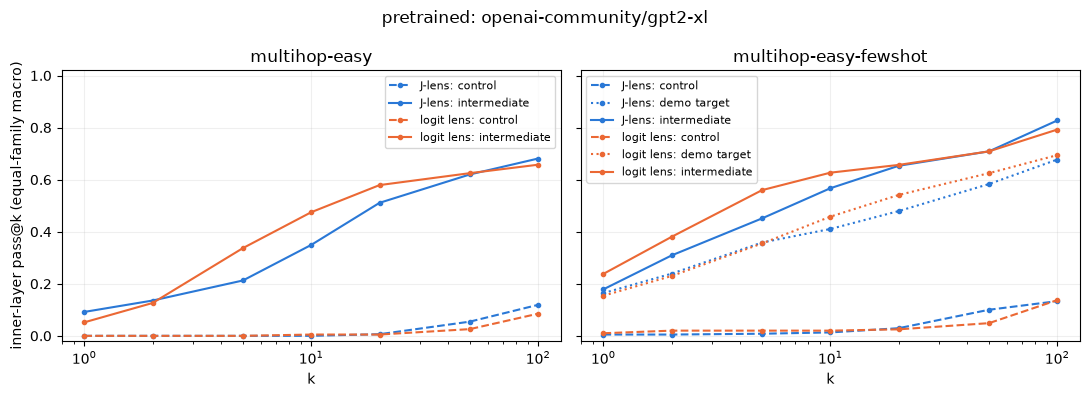

In [13]:
curves = main[main.kind.isin(["intermediate", "control", "demo target"])]
auc = pd.DataFrame([
    dict(zip(["dataset", "lens", "kind"], keys, strict=True),
         auc=np.trapezoid(group.sort_values("k").score, np.log(group.sort_values("k").k)) / np.log(100))
    for keys, group in curves.groupby(["dataset", "lens", "kind"])
])
display(auc.pivot(index="kind", columns=["dataset", "lens"], values="auc").round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, dataset in zip(axes, [ZERO_SHOT, FEW_SHOT], strict=True):
    for (lens_name, kind), line in curves[curves.dataset.eq(dataset)].groupby(["lens", "kind"]):
        ax.plot(line.k, line.score, color=COLORS[lens_name], linestyle=STYLES[kind],
                marker="o", ms=3, label=f"{lens_name}: {kind}")
    ax.set(xscale="log", ylim=(-0.02, 1.02), title=dataset, xlabel="k")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel("inner-layer pass@k (equal-family macro)")
fig.suptitle(f"{RUN_MODE}: {run_model_id}")
fig.tight_layout()
fig.savefig(RUN_DIR / "inner_pass_at_k.png", dpi=140)
plt.show()

## Where: layer profiles

Share of words with rank ≤ K at each block output, aggregated phrasing → base → family → equal-family mean. Depth is block index / (number of blocks − 1); 100% is the shared final output. A latent bridge should peak before the target rises.

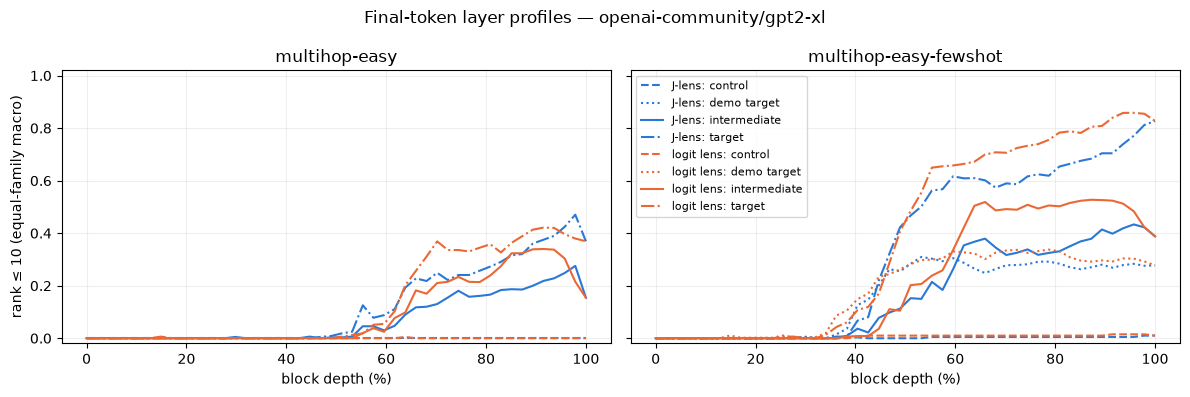

peak                                                peak_depth                                            
dataset      multihop-easy            multihop-easy-fewshot            multihop-easy            multihop-easy-fewshot           
lens                J-lens logit lens                J-lens logit lens        J-lens logit lens                J-lens logit lens
kind                                                                                                                            
control               0.00       0.00                  0.01       0.02          0.00      63.83                 97.87      91.49
demo target            NaN        NaN                  0.31       0.34           NaN        NaN                 53.19      78.72
intermediate          0.28       0.34                  0.43       0.53         97.87      91.49                 95.74      87.23
target                0.47       0.42                  0.83       0.86         97.87      91.49                100.00      95.74

In [14]:
depth = np.linspace(0, 100, N_LAYERS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
profile_rows = []
for ax, dataset in zip(axes, [ZERO_SHOT, FEW_SHOT], strict=True):
    frame = easy_words[easy_words.dataset.eq(dataset) & easy_words.ranks.notna()]
    for (lens_name, kind), group in frame.groupby(["lens", "kind"]):
        layer_hits = pd.DataFrame((np.stack(group.ranks) <= K).astype(float), index=group.index)
        _, _, families = macro(pd.concat([group[HIERARCHY], layer_hits], axis=1), list(layer_hits.columns))
        curve = families.mean()
        profile_rows.append({"dataset": dataset, "lens": lens_name, "kind": kind,
                             "peak_depth": depth[int(curve.argmax())], "peak": curve.max()})
        ax.plot(depth, curve, color=COLORS[lens_name], linestyle=STYLES[kind], label=f"{lens_name}: {kind}")
    ax.set(title=dataset, xlabel="block depth (%)", ylim=(-0.02, 1.02))
    ax.grid(alpha=0.2)
axes[0].set_ylabel(f"rank ≤ {K} (equal-family macro)")
axes[-1].legend(fontsize=8)
fig.suptitle(f"Final-token layer profiles — {run_model_id}")
fig.tight_layout()
fig.savefig(RUN_DIR / "layer_profiles.png", dpi=140)
plt.show()
display(pd.DataFrame(profile_rows).pivot(
    index="kind", columns=["dataset", "lens"], values=["peak", "peak_depth"],
).round(2))

## Paired comparisons

Per intermediate occurrence (prompt-level, not macro): best inner-layer rank for the J-lens against the logit lens, and for the same prompt with and without demonstrations. A positive log10 gain means the first column finds the word at a better rank.

In [15]:
inter = easy_words[easy_words.kind.eq("intermediate") & easy_words.ranks.notna()].copy()
inter["inner_best"] = inter.ranks.map(lambda r: int(r[:-1].min()))
paired = inter.pivot(index=["dataset", "family", "item", "word"], columns="lens", values="inner_best")
paired["log10 gain"] = np.log10(paired["logit lens"]) - np.log10(paired["J-lens"])
paired["winner"] = np.select(
    [paired["J-lens"] < paired["logit lens"], paired["J-lens"] > paired["logit lens"]],
    ["J-lens", "logit lens"], default="tie",
)
display(paired.groupby("dataset").winner.value_counts().unstack(fill_value=0)
        .reindex(columns=["J-lens", "logit lens", "tie"], fill_value=0))
display(paired.groupby(["dataset", "family"])[["J-lens", "logit lens"]].median())

shots = inter.pivot(index=["lens", "family", "item", "word"], columns="dataset", values="inner_best")
shots["few-shot better"] = shots[FEW_SHOT] < shots[ZERO_SHOT]
shots["few-shot worse"] = shots[FEW_SHOT] > shots[ZERO_SHOT]
display(shots.groupby("lens").agg(
    median_zero_shot=(ZERO_SHOT, "median"), median_few_shot=(FEW_SHOT, "median"),
    few_shot_better=("few-shot better", "sum"), few_shot_worse=("few-shot worse", "sum"),
))
fewshot_paired = paired.loc[FEW_SHOT]
display(fewshot_paired.sort_values("log10 gain", ascending=False).head(8))
display(fewshot_paired.sort_values("log10 gain").head(8))

winner,J-lens,logit lens,tie
dataset,,,
multihop-easy,77,106,17
multihop-easy-fewshot,56,90,54


lens                              J-lens  logit lens
dataset               family                        
multihop-easy         animals      482.5       645.0
                      arithmetic   160.0       196.0
                      geography      3.0         3.5
                      opposites     10.5         7.5
                      word_forms    15.0         6.5
multihop-easy-fewshot animals       70.5        86.0
                      arithmetic    84.5       108.0
                      geography      2.0         2.0
                      opposites      1.0         1.0
                      word_forms    10.0         4.0

,median_zero_shot,median_few_shot,few_shot_better,few_shot_worse
lens,,,,
J-lens,15.0,4.0,137,36
logit lens,9.0,3.0,147,27


lens                                           J-lens  logit lens  log10 gain  winner
family     item                      word                                            
arithmetic 9-minus-6-times-4-v1      three         59         349    0.771973  J-lens
geography  italy-country_language-v2 Italy          1           5    0.698970  J-lens
animals    elephant-legs-v1          elephant      19          86    0.655745  J-lens
arithmetic 8-minus-5-times-2-v1      three         64         257    0.603753  J-lens
geography  italy-country_language-v1 Italy          1           4    0.602060  J-lens
animals    elephant-legs-v2          elephant      62         231    0.571220  J-lens
           duck-legs-v1              duck          80         250    0.494850  J-lens
geography  spain-country_language-v2 Spain          1           3    0.477121  J-lens

lens                                J-lens  logit lens  log10 gain      winner
family     item              word                                             
word_forms child-plural-v1   child      35           2   -1.243038  logit lens
           child-plural-v2   child      17           1   -1.230449  logit lens
animals    ant-legs-v1       ant      1138         229   -0.696307  logit lens
           ant-legs-v2       ant      1226         254   -0.683657  logit lens
word_forms tooth-plural-v2   tooth      13           3   -0.636822  logit lens
           man-plural-v1     man        17           4   -0.628389  logit lens
animals    cow-young-v2      cow         4           1   -0.602060  logit lens
opposites  stone-opposite-v1 hard        4           1   -0.602060  logit lens

## Conclusions

Run: `openai-community/gpt2-xl` at `15ea56de`, float32, BOS prepended, lens `snapshot_lens_134.pt` (fit on `FIT_MIX x 0.25`, 134 prompts, sequence length 128; same lens as the reference benchmark). The zero-shot column reproduces the reference notebook exactly (inner pass@10 macro 0.349 / 0.475, generated 34/200).

1. **Few-shot makes the base model answer.** Generated accuracy 17.0% → 44.5%, next-token top-1 14.8% → 43.4%, and no truncated answers: the model now completes `" honey.\n"` in the demonstrated format. Gains are concentrated in geography (41% → 97%) and word forms (29% → 54%); animals rise to 25%, arithmetic stays at 9% (GPT-2 XL cannot do the arithmetic), opposites at 2.5%.
2. **The intermediate is more visible with demonstrations, for both lenses.** Inner-layer macro pass@10: J-lens 34.9% → 56.7%, logit lens 47.5% → 62.7%; the median best inner rank of the intermediate drops from 15 to 4 (J-lens) and from 9 to 3 (logit lens), improving for ~70% of prompts.
3. **The J-lens does not outperform the logit lens on this dataset.** It is 6.0 pp behind at pass@10 few-shot (12.6 pp zero-shot), behind in dev, test and the generated-correct subset, and loses the paired rank comparison 56 : 90 (54 ties). It is ahead only in the tails (pass@1 zero-shot 9.2% vs 5.2%; pass@100 82.8% vs 79.2% few-shot) and on part of animals (`elephant`, `duck`) and arithmetic (`three`); it loses clearly on word forms (`child`, `tooth`, `man`) and on `ant`. This is the opposite of the latent-bridge result, where J-lens advantage comes from non-final positions; at the final token the logit lens is already well calibrated for GPT-2 XL.
4. **High intermediate scores are partly output, not latent reasoning.** In opposites the model's answer *is* the intermediate (`" empty"` for "the opposite of a bottle with nothing inside"), so its 100% pass@10 is the next-token prediction; final-only pass@10 of the intermediate is already 38.8% few-shot. The generated-correct split (89 prompts) avoids this and keeps the same ordering of lenses.
5. **Baselines.** Shifted controls stay at 1–2%, so the intermediate signal is item specific. Demo targets — answers present in the context — reach 41% (J-lens) and 46% (logit lens), close to the intermediates, and rise at the same depth as the target (~40–55%). In-context copying of recent answers is therefore a strong competitor at this readout, and few-shot visibility should be compared against it rather than against zero.
6. **No evidence of a bridge preceding the answer.** In the few-shot layer profile the target rises first (from ~40% depth) and the intermediate follows (~55–65%), peaking at 88–96% depth. Readability of a word is not causal evidence that the model uses it.

Caveats: one fitted lens on a small fit corpus, a single position, descriptive scores without uncertainty intervals (`group_id` is retained for clustered intervals), and 44 prompts whose demonstrations come from a different relation (`demo_relation_match`).

In [16]:
lines = []
if RUN_MODE == "smoke":
    lines.append("**Offline smoke only:** random tiny Llama plus identity Jacobians; "
                 "these results validate execution, not trained-model quality.")
else:
    lines.append(f"**Model:** `{run_model_id}` at `{resolved_revision}`; dtype `{run_dtype}`; BOS `{BOS_POLICY}`.")
for dataset in [ZERO_SHOT, FEW_SHOT]:
    row = by_dataset.loc[dataset]
    lines.append(f"{dataset}: generated answers correct {row.generated_accuracy:.1%} "
                 f"({int(row.generated)}/{int(row.prompts)}), next-token top-1 {row.top1_accuracy:.1%}.")
for (dataset, kind), group in main[main.k.eq(K)].groupby(["dataset", "kind"]):
    rates = group.set_index("lens").score
    lines.append(f"{dataset}, {kind}: inner-layer macro pass@{K}, J-lens {rates['J-lens']:.1%}, "
                 f"logit lens {rates['logit lens']:.1%} ({100 * (rates['J-lens'] - rates['logit lens']):+.1f} pp).")
display(Markdown("\n\n".join(f"* {line}" for line in lines)))
easy_scores.to_csv(RUN_DIR / "multihop_easy_fewshot_scores.csv", index=False)
auc.to_csv(RUN_DIR / "auc.csv", index=False)
by_dataset.to_csv(RUN_DIR / "answer_accuracy.csv")
print("Rank cache, provenance, tables and figures:", RUN_DIR.relative_to(REPO))

* **Model:** `openai-community/gpt2-xl` at `15ea56dee5df4983c59b2538573817e1667135e2`; dtype `torch.float32`; BOS `prepend`.

* multihop-easy: generated answers correct 17.0% (34/200), next-token top-1 14.8%.

* multihop-easy-fewshot: generated answers correct 44.5% (89/200), next-token top-1 43.4%.

* multihop-easy, control: inner-layer macro pass@10, J-lens 0.0%, logit lens 0.5% (-0.5 pp).

* multihop-easy, intermediate: inner-layer macro pass@10, J-lens 34.9%, logit lens 47.5% (-12.6 pp).

* multihop-easy, target: inner-layer macro pass@10, J-lens 54.8%, logit lens 52.3% (+2.5 pp).

* multihop-easy-fewshot, control: inner-layer macro pass@10, J-lens 1.3%, logit lens 2.0% (-0.7 pp).

* multihop-easy-fewshot, demo target: inner-layer macro pass@10, J-lens 41.1%, logit lens 45.8% (-4.7 pp).

* multihop-easy-fewshot, intermediate: inner-layer macro pass@10, J-lens 56.7%, logit lens 62.7% (-6.0 pp).

* multihop-easy-fewshot, target: inner-layer macro pass@10, J-lens 90.2%, logit lens 91.4% (-1.2 pp).

Rank cache, provenance, tables and figures: runs/multihop-easy-fewshot-benchmark/55030581eccca6e6eb83
